# Advanced Algorithms: Parallel and External-Memory Algorithms

> **Prerequisite:** [`dsa/01` complexity](../dsa/01_complexity_analysis_and_recursion.ipynb), [`dsa/03` sorting](../dsa/03_searching_and_sorting.ipynb) (merge sort) and [`dsa/08` divide and conquer](../dsa/08_greedy_and_divide_and_conquer.ipynb). Helpful: [`23_Software_Engineering/05` concurrency and async](../../23_Software_Engineering/05_concurrency_and_async.ipynb), which teaches the *tools* (threads, processes, the GIL); this notebook teaches the *algorithms and their analysis*.
>
> **Who is this for:** students taking a "Parallel and Distributed Computing" or "Advanced Algorithms" course (the HEC BS-AI core includes one), and engineers who want to know why their 8-core job only ran 3× faster, why GPUs love prefix sums, and how data larger than RAM gets sorted.
>
> **What you will learn:**
> - The **work–span (DAG) model** and the **PRAM** model; work law, span law, parallelism and **Brent's theorem**, verified by simulating a greedy scheduler
> - **Amdahl's law** and **Gustafson's law**, demonstrated cleanly and then measured on real processes
> - **Parallel reduction** and **parallel prefix sum** (Hillis–Steele and **Blelloch** scans), operation counts, stream compaction, and the associative scan behind state-space models such as Mamba
> - **Parallel merge sort** and **sample sort** on processes, and the real overheads: process start-up and pickling
> - **Embarrassingly parallel** patterns: map, chunking, **static vs dynamic scheduling** and load balancing
> - The **external-memory model** (block size $B$, memory $M$) and an **external merge sort** of a file larger than the memory limit, with **every block I/O counted** and matched to the formula
> - **Cache-aware and cache-oblivious** ideas: blocked matrix multiplication, with simulated cache misses and real timings (NumPy, pure Python, numba)
> - Distributed basics: **MapReduce** algorithms (word count, matrix multiply, join) and **ring all-reduce**, simulated in-process with traffic counted
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb), NumPy basics, Big-O.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. It uses at most 4 worker processes and runs in about 2–3 minutes. Timings depend on your machine and on what else is running; the text never relies on exact timing values.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows CLRS (4th ed.) ch. 26 "Parallel Algorithms", Blelloch's "Prefix Sums and Their Applications" (1990) and Aggarwal & Vitter's external-memory model (1988).

## Explained simply

A computer today has many "workers" (CPU cores, or thousands of tiny GPU cores), and the data we care about is often bigger than its memory. This notebook is about two questions: **how do you split a job so many workers can share it**, and **how do you process data that does not fit in memory**? Splitting is not free: some steps must wait for others, workers need to be told what to do, and results have to be combined. Moving data is not free either: reading from disk is thousands of times slower than reading from memory, so good algorithms read data in big chunks and as few times as possible. Knowing these rules explains why 8 cores rarely give an 8× speed-up and why GPUs and big-data systems are designed the way they are.

**Everyday analogies.**
- **Parallel work** is like painting a fence with friends: 4 painters finish about 4× faster, but if someone must first fetch the paint alone (a **serial** step), that part does not get faster no matter how many friends help. That is **Amdahl's law**.
- **External-memory sorting** is like sorting a huge pile of exam papers on a small desk: you sort a desk-sized stack at a time into neat piles, then merge the piles by repeatedly taking the top paper with the lowest mark.
- **All-reduce** is like a group of friends adding up their pocket money by passing notes around a circle, instead of everyone shouting at one person.

**A tiny example.** Adding 8 numbers one by one takes 7 steps. With 4 helpers: in step 1, four pairs are added at the same time (8 → 4 numbers), in step 2 two pairs (4 → 2), in step 3 one pair (2 → 1). Still 7 additions in total (the **work**), but only **3** steps of waiting (the **span**), because $\log_2 8 = 3$.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Work and span | total effort vs the longest chain of steps that must happen in order | why a GPU can sum a million numbers in about 20 rounds |
| Amdahl's law | the part you cannot split limits the speed-up | data loading that stalls multi-GPU training |
| External memory | data bigger than RAM, read in big blocks | sorting and de-duplicating LLM training data on disk |

## 0. Setup

> 💬 **In plain English:** load the tools and write a small helper module that worker processes can import.

Worker processes need to **import** the functions they run (they receive them by pickling a reference, not the code). So we write a tiny module into a temporary folder and put that folder on `sys.path`; `23_Software_Engineering/05` explains why in detail.

In [1]:
import bisect, heapq, itertools, math, os, pickle, random, shutil, sys, tempfile, time, zlib
from collections import Counter, OrderedDict, defaultdict
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

random.seed(0); np.random.seed(0)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)

WORK = Path(tempfile.mkdtemp(prefix="aa10_"))           # every file this notebook creates lives here
MAX_WORKERS = min(4, os.cpu_count() or 1)               # stay polite on shared machines

(WORK / "aa10_workers.py").write_text("""
import time
import numpy as np

def busy(n):
    # pure-Python CPU-bound loop (holds the GIL, so only processes can run it in parallel)
    s = 0
    for i in range(n):
        s += i * i % 7
    return s

def busy_cpu_seconds(n):
    t0 = time.process_time()
    busy(n)
    return time.process_time() - t0

def merge_sort(xs):
    # plain top-down merge sort in pure Python
    if len(xs) <= 1:
        return list(xs)
    mid = len(xs) // 2
    a, b = merge_sort(xs[:mid]), merge_sort(xs[mid:])
    out, i, j = [], 0, 0
    while i < len(a) and j < len(b):
        if a[i] <= b[j]:
            out.append(a[i]); i += 1
        else:
            out.append(b[j]); j += 1
    out.extend(a[i:]); out.extend(b[j:])
    return out

def chunk_sum(a):
    return a.sum()

def chunk_scan(args):
    a, offset = args
    return np.cumsum(a) + offset

def square(x):
    return x * x
""")
sys.path.insert(0, str(WORK))
import aa10_workers as W

print("Python", sys.version.split()[0], "| logical CPUs:", os.cpu_count(), "| worker processes used:", MAX_WORKERS)

Python 3.12.3 | logical CPUs: 8 | worker processes used: 4


## 1. Models of parallel computation: work, span and PRAM

> 💬 **In plain English:** measure a parallel algorithm by its total work and its longest chain of dependent steps.

**Intuition.** Think of a recipe as a set of steps with arrows "must happen before". Two cooks can do independent steps at the same time, but nobody can shorten the longest chain of dependent steps (you cannot ice a cake before baking it).

**Definitions (CLRS ch. 26).** A parallel computation is a **DAG**: nodes are unit-time operations, edges are dependencies.
- **Work** $T_1$: the total number of operations, i.e. the running time on **1** processor.
- **Span** $T_\infty$ (also *depth* or *critical-path length*): the number of nodes on the **longest path**, i.e. the time with **unlimited** processors.
- $T_p$: the running time on $p$ processors.
- **Work law** $T_p \ge T_1 / p$ ($p$ processors do at most $p$ operations per step). **Span law** $T_p \ge T_\infty$.
- **Parallelism** $T_1 / T_\infty$: the maximum useful number of processors. Speed-up $T_1/T_p$ can never exceed it.
- **Brent's theorem / greedy-scheduler bound:** any greedy scheduler (never idles a processor while some operation is ready) achieves $T_p \le T_1/p + T_\infty$. So it is always within a factor of 2 of optimal.

**PRAM** (parallel random-access machine): $p$ synchronous processors sharing one memory; each step every processor does one operation. Variants differ in simultaneous access: **EREW** (exclusive read, exclusive write), **CREW** (concurrent read), **CRCW** (concurrent read and write, with a rule such as "arbitrary writer wins"). PRAM ignores communication costs, which is why we will also look at measured overheads.

**Worked example: summing 8 numbers with a tree.**

```
level 0:  x0  x1  x2  x3  x4  x5  x6  x7      (inputs)
level 1:   x0+x1   x2+x3   x4+x5   x6+x7      4 additions in parallel
level 2:       s01+s23        s45+s67         2 additions
level 3:              total                   1 addition
work T1 = 7 additions, span T_inf = 3 levels, parallelism = 7/3
```

      n  work T1  span T_inf  parallelism T1/T_inf
      8        7           3                   2.3
     64       63           6                  10.5
   1024     1023          10                 102.3
1048576  1048575          20               52428.8


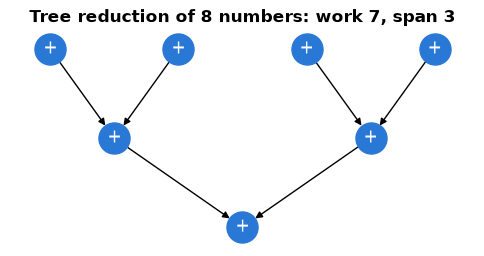

In [2]:
def reduction_dag(n):
    """DAG of a balanced tree sum of n inputs (n a power of two). Nodes are additions."""
    G, level, nid = nx.DiGraph(), [("in", i) for i in range(n)], 0
    depth = 0
    while len(level) > 1:
        depth += 1
        nxt = []
        for a, b in zip(level[0::2], level[1::2]):
            node = ("add", nid); nid += 1
            G.add_node(node, depth=depth)
            for child in (a, b):
                if child[0] == "add":
                    G.add_edge(child, node)
            nxt.append(node)
        level = nxt
    return G

def work_span(G):
    """Work = number of operation nodes; span = number of nodes on the longest path."""
    return G.number_of_nodes(), nx.dag_longest_path_length(G) + 1

rows = []
for n in [8, 64, 1024, 2 ** 20]:
    T1, Tinf = (n - 1, int(math.log2(n))) if n > 1024 else work_span(reduction_dag(n))
    rows.append((n, T1, Tinf, T1 / Tinf))
print(pd.DataFrame(rows, columns=["n", "work T1", "span T_inf", "parallelism T1/T_inf"]).round(1).to_string(index=False))

G8 = reduction_dag(8)
pos = {}
for d in range(1, 4):
    layer = sorted([v for v in G8 if G8.nodes[v]["depth"] == d], key=lambda v: v[1])
    for i, v in enumerate(layer):
        pos[v] = ((i + 0.5) * 8 / len(layer), -d)
fig, ax = plt.subplots(figsize=(6, 2.8))
nx.draw_networkx(G8, pos, ax=ax, labels={v: "+" for v in G8}, node_color="#2a78d6", font_color="white", node_size=500)
ax.set_title("Tree reduction of 8 numbers: work 7, span 3"); ax.axis("off"); plt.show()

**What just happened?** For $n$ inputs the tree does $n - 1$ additions (the same work as the sequential loop) in only $\log_2 n$ levels. For a million numbers ($2^{20}$) the span is just 20, so the parallelism is about 52,000: far more than any CPU has cores, which is why GPUs (with thousands of lanes) are good at reductions.

Now let us **check Brent's bound** by simulating a greedy scheduler on random DAGs: at every step, run up to $p$ ready operations.

In [3]:
def random_dag(n_nodes, edge_prob, rng):
    """Random DAG: edges only go from lower to higher node ids, so there is no cycle."""
    G = nx.DiGraph(); G.add_nodes_from(range(n_nodes))
    for u in range(n_nodes):
        for v in range(u + 1, min(n_nodes, u + 12)):          # local dependencies, like real programs
            if rng.random() < edge_prob:
                G.add_edge(u, v)
    return G

def greedy_schedule(G, p):
    """Unit-time ops; each step executes up to p ready nodes (all predecessors done). Returns T_p."""
    indeg = dict(G.in_degree())
    ready = sorted(v for v in G if indeg[v] == 0)
    steps = 0
    while ready:
        steps += 1
        run, ready = ready[:p], ready[p:]                       # greedy: never idle if work is ready
        for u in run:
            for v in G.successors(u):
                indeg[v] -= 1
                if indeg[v] == 0:
                    ready.append(v)
    return steps

rng = random.Random(1)
rows = []
for trial in range(30):
    G = random_dag(rng.randint(50, 400), rng.uniform(0.05, 0.5), rng)
    T1, Tinf = work_span(G)
    for p in [1, 2, 4, 8, 32]:
        Tp = greedy_schedule(G, p)
        assert max(T1 / p, Tinf) <= Tp <= T1 / p + Tinf          # work law, span law, Brent's bound
        rows.append((trial, T1, Tinf, p, Tp, T1 / Tp))
sched = pd.DataFrame(rows, columns=["dag", "T1", "T_inf", "p", "T_p", "speed-up"])
print("bounds held for", len(sched), "(DAG, p) pairs")
print(sched[sched.dag < 2].round(2).to_string(index=False))

bounds held for 150 (DAG, p) pairs
 dag  T1  T_inf  p  T_p  speed-up
   0 118     47  1  118      1.00
   0 118     47  2   65      1.82
   0 118     47  4   47      2.51
   0 118     47  8   47      2.51
   0 118     47 32   47      2.51
   1 180      6  1  180      1.00
   1 180      6  2   90      2.00
   1 180      6  4   46      3.91
   1 180      6  8   24      7.50
   1 180      6 32    8     22.50


**What just happened?** On 30 random DAGs and 5 processor counts, the greedy schedule always landed between the lower bound $\max(T_1/p, T_\infty)$ and Brent's upper bound $T_1/p + T_\infty$. Notice in the printed rows how the speed-up stops growing once $p$ passes the parallelism $T_1/T_\infty$: extra processors just sit idle waiting for the critical path.

🎓 **Exam tip:** to analyse a parallel algorithm, give **work** and **span** separately, then the parallelism. An algorithm is **work-efficient** if its work matches the best sequential algorithm (up to a constant).

## 2. Amdahl's law and Gustafson's law

> 💬 **In plain English:** the serial part of a program caps its speed-up (Amdahl), unless the problem grows with the machine (Gustafson).

**Intuition.** If 10% of a job can only be done by one worker, then even infinitely many workers leave that 10%: the job can never get more than 10× faster.

**Amdahl's law (1967), strong scaling (fixed problem size).** With serial fraction $s$ of the one-processor time,
$$S(p) = \frac{T_1}{T_p} = \frac{1}{s + \frac{1 - s}{p}} \xrightarrow{p \to \infty} \frac{1}{s}.$$

**Gustafson's law (1988), weak scaling (problem grows with $p$).** If the parallel part grows so the run *time* stays fixed, with $s$ now the serial fraction of the *parallel* run, the **scaled speed-up** is
$$S_{\text{scaled}}(p) = s + p(1 - s),$$
which grows without limit. Both are right; they answer different questions ("same job faster?" vs "bigger job in the same time?").

| $s$ | Amdahl $S(8)$ | Amdahl limit $1/s$ | Gustafson $S(8)$ |
|---|---|---|---|
| 0.05 | 5.93 | 20 | 7.65 |
| 0.10 | 4.71 | 10 | 7.30 |
| 0.25 | 2.91 | 4 | 6.25 |

s=0.05: Amdahl S(8)=5.93, limit 20, Gustafson S(8)=7.65
s=0.10: Amdahl S(8)=4.71, limit 10, Gustafson S(8)=7.30
s=0.25: Amdahl S(8)=2.91, limit 4, Gustafson S(8)=6.25


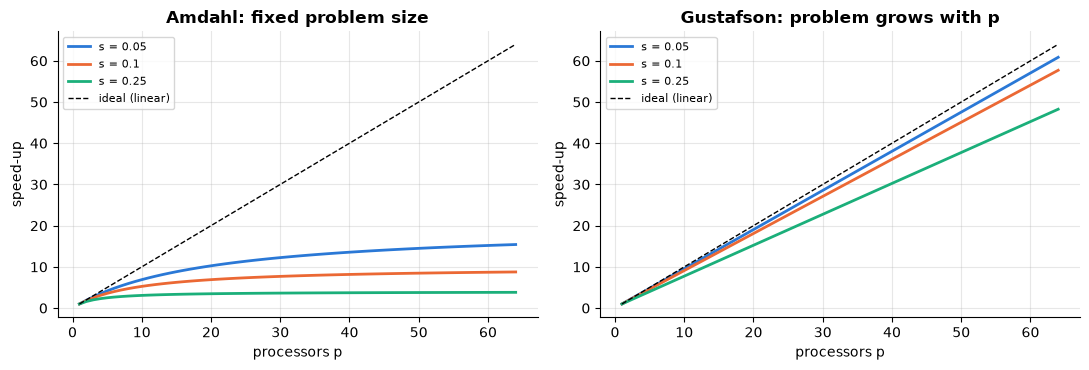

In [4]:
amdahl = lambda s, p: 1 / (s + (1 - s) / p)
gustafson = lambda s, p: s + p * (1 - s)
for s in [0.05, 0.10, 0.25]:                           # the table above, recomputed
    print(f"s={s:.2f}: Amdahl S(8)={amdahl(s, 8):.2f}, limit {1 / s:.0f}, Gustafson S(8)={gustafson(s, 8):.2f}")

ps = np.arange(1, 65)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for s in [0.05, 0.10, 0.25]:
    axes[0].plot(ps, amdahl(s, ps), label=f"s = {s}")
    axes[1].plot(ps, gustafson(s, ps), label=f"s = {s}")
for ax, title in zip(axes, ["Amdahl: fixed problem size", "Gustafson: problem grows with p"]):
    ax.plot(ps, ps, "k--", lw=1, label="ideal (linear)")
    ax.set_xlabel("processors p"); ax.set_ylabel("speed-up"); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**A clean-room demonstration.** Real CPU timings on a shared machine are noisy, so first we demonstrate the *laws themselves* with tasks of known length. Each task "works" by sleeping for 100 ms; sleeping threads truly run in parallel (sleep releases the GIL), so this behaves like an ideal machine with no overheads. The job has a 200 ms serial part plus 16 parallel tasks (1.6 s), so $s = 0.2/1.8 = 1/9$.

In [5]:
TASK, SERIAL, N_TASKS = 0.100, 0.200, 16

def run_job(p, n_tasks):
    with ThreadPoolExecutor(p) as pool:
        list(pool.map(time.sleep, [0] * p))              # start the worker threads before the clock starts
        t0 = time.perf_counter()
        time.sleep(SERIAL)                               # serial part: e.g. loading the config and data
        list(pool.map(time.sleep, [TASK] * n_tasks))     # parallel part
        return time.perf_counter() - t0

rows = []
for p in [1, 2, 4, 8, 16]:
    strong = run_job(p, N_TASKS)                         # same job, more workers
    weak = run_job(p, 4 * p)                             # 4 tasks per worker: the job grows with p
    weak_serial_equiv = SERIAL + 4 * p * TASK            # how long the grown job would take on 1 worker
    rows.append((p, strong, (SERIAL + N_TASKS * TASK) / strong, amdahl(1 / 9, p),
                 weak, weak_serial_equiv / weak, gustafson(SERIAL / (SERIAL + 4 * TASK), p)))
clean = pd.DataFrame(rows, columns=["p", "time (fixed job)", "speed-up", "Amdahl s=1/9",
                                    "time (growing job)", "scaled speed-up", "Gustafson s=1/3"]).round(3)
print(clean.to_string(index=False))
assert np.allclose(clean["speed-up"], clean["Amdahl s=1/9"], rtol=0.2)
assert np.allclose(clean["scaled speed-up"], clean["Gustafson s=1/3"], rtol=0.2)

 p  time (fixed job)  speed-up  Amdahl s=1/9  time (growing job)  scaled speed-up  Gustafson s=1/3
 1             1.814     0.992           1.0               0.601            0.999            1.000
 2             1.003     1.794           1.8               0.602            1.662            1.667
 4             0.602     2.990           3.0               0.612            2.942            3.000
 8             0.408     4.413           4.5               0.609            5.583            5.667
16             0.310     5.813           6.0               0.612           10.776           11.000


**What just happened?** The measured speed-ups match Amdahl's formula within 20% (checked by the `assert`; on a lightly loaded machine they agree within a few percent): with 16 workers the fixed job is only about 6× faster, because the 200 ms serial part never shrinks. With the growing job, the run time stays about constant while the work grows, and the scaled speed-up follows Gustafson's line $s + p(1-s)$ with $s = 1/3$.

**Now on real hardware.** Next we split a **CPU-bound** pure-Python loop across worker **processes** (threads would not help: the GIL lets only one thread run Python bytecode at a time). We also measure the CPU time each worker really used.

In [6]:
TOTAL, SERIAL_N = 3_000_000, 300_000                     # loop iterations: parallel part and serial part

def real_job(pool, p):
    t0 = time.perf_counter()
    W.busy(SERIAL_N)                                     # serial part runs in the parent
    cpu = sum(pool.map(W.busy_cpu_seconds, [TOTAL // p] * p))   # parallel part, split evenly
    return time.perf_counter() - t0, cpu

rows = []
for p in sorted({1, 2, MAX_WORKERS}):
    with ProcessPoolExecutor(p) as pool:
        list(pool.map(W.square, range(p)))               # warm-up: start the processes before timing
        best = min((real_job(pool, p) for _ in range(3)), key=lambda r: r[0])
    rows.append((p, *best))
real = pd.DataFrame(rows, columns=["p", "wall s", "worker CPU s"])
real["speed-up"] = real["wall s"].iloc[0] / real["wall s"]
real["efficiency"] = real["speed-up"] / real["p"]
t0 = time.process_time(); W.busy(SERIAL_N); serial_cpu = time.process_time() - t0
s_designed = serial_cpu / (serial_cpu + real["worker CPU s"].iloc[0])
real["Amdahl prediction"] = [amdahl(s_designed, p) for p in real.p]
print(real.round(3).to_string(index=False))
print(f"designed serial fraction (from CPU times): {s_designed:.3f}")
gap = real["Amdahl prediction"].iloc[-1] - real["speed-up"].iloc[-1]
print(f"with p={real.p.iloc[-1]}: measured speed-up {real['speed-up'].iloc[-1]:.2f} vs Amdahl {real['Amdahl prediction'].iloc[-1]:.2f}"
      f" -> {'below' if gap > 0 else 'at or above'} the prediction by {abs(gap):.2f}")

 p  wall s  worker CPU s  speed-up  efficiency  Amdahl prediction
 1   0.728         0.644     1.000        1.00              1.000
 2   0.473         0.606     1.540        0.77              1.833
 4   0.405         0.694     1.798        0.45              3.142
designed serial fraction (from CPU times): 0.091
with p=4: measured speed-up 1.80 vs Amdahl 3.14 -> below the prediction by 1.34


**What just happened?** The table shows wall time, the total CPU time the workers used, the measured speed-up and Amdahl's prediction for the serial fraction we built in. On real hardware the measured speed-up is usually **below** the prediction, and the last printed line tells you by how much on this run. The reasons are everything the clean model ignores: sending tasks and results between processes, worker start-up, other programs competing for the same cores, shared caches and memory bandwidth, and CPUs lowering their clock speed when many cores are busy. If the "worker CPU" column grows with $p$, the workers really did more total work (contention), not just waited.

⚠️ **Common mistake:** quoting speed-up relative to a slow serial baseline. Always compare against the **best serial implementation**; a vectorised NumPy version of this loop on 1 core would beat the 4-process pure-Python version.

## 3. Parallel reduction and parallel prefix sum (scan)

> 💬 **In plain English:** running totals look sequential, but a clever tree of additions computes them in a logarithmic number of rounds.

**Intuition.** Running totals look hopelessly sequential: total number 5 needs total number 4. The trick is that addition is **associative**, so partial sums of different pieces can be computed at the same time and combined.

**Definitions.** Given $x_0, \dots, x_{n-1}$ and an associative operator $\oplus$ with identity $0$:
- the **inclusive scan** is $y_i = x_0 \oplus \dots \oplus x_i$ (`np.cumsum`);
- the **exclusive scan** is $y_i = x_0 \oplus \dots \oplus x_{i-1}$, with $y_0 = 0$.

The sequential loop has work $n - 1$ but span $n - 1$. Two classic parallel algorithms:

| Algorithm | Work | Span | Work-efficient? |
|---|---|---|---|
| sequential loop | $n - 1$ | $n - 1$ | yes |
| **Hillis–Steele** (1986) | $\Theta(n \log n)$ | $\log_2 n$ | no |
| **Blelloch** (1990): up-sweep + down-sweep | $2(n - 1)$ additions | $2 \log_2 n$ | yes |

**Hillis–Steele by hand** ($n = 8$, all ones): at step $d$, every position $i \ge 2^d$ adds the value $2^d$ places to its left, simultaneously.

| step | offset | x0 | x1 | x2 | x3 | x4 | x5 | x6 | x7 |
|---|---|---|---|---|---|---|---|---|---|
| start | | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 1 |
| 1 | 1 | 1 | 2 | 2 | 2 | 2 | 2 | 2 | 2 |
| 2 | 2 | 1 | 2 | 3 | 4 | 4 | 4 | 4 | 4 |
| 3 | 4 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |

Each NumPy line below performs one PRAM step: all its additions are independent, so $p \ge n$ processors could do them at once.

In [7]:
OPS = Counter()                                     # additions performed, to measure work

def hillis_steele_scan(x):
    """Inclusive scan, log2(n) steps. Each step is one vectorised (= one parallel) update."""
    y = np.array(x, dtype=np.int64)
    steps, d = 0, 1
    while d < len(y):
        new = y.copy()                              # double buffering: everyone reads the OLD values
        new[d:] = y[d:] + y[:-d]
        OPS["hillis_steele"] += len(y) - d
        y, d, steps = new, 2 * d, steps + 1
    return y, steps

def blelloch_scan(x):
    """Exclusive scan (n a power of two): up-sweep builds a sum tree, down-sweep pushes prefixes down."""
    a = np.array(x, dtype=np.int64)
    n, steps = len(a), 0
    d = 1
    while d < n:                                    # up-sweep (reduce): a[k + 2d - 1] += a[k + d - 1]
        a[2 * d - 1::2 * d] += a[d - 1::2 * d]
        OPS["blelloch"] += n // (2 * d)
        d, steps = 2 * d, steps + 1
    total = a[-1]
    a[-1] = 0                                       # identity at the root
    d = n // 2
    while d >= 1:                                   # down-sweep: left child gets parent, right gets parent + old left
        left = a[d - 1::2 * d].copy()
        a[d - 1::2 * d] = a[2 * d - 1::2 * d]
        a[2 * d - 1::2 * d] += left
        OPS["blelloch"] += n // (2 * d)
        d, steps = d // 2, steps + 1
    return a, steps, total

x = [3, 1, 7, 0, 4, 1, 6, 3]                        # Blelloch's classic example
inc, hs_steps = hillis_steele_scan(x)
exc, bl_steps, total = blelloch_scan(x)
print("input            :", x)
print("Hillis-Steele    :", inc.tolist(), f"({hs_steps} steps)")
print("Blelloch (excl.) :", exc.tolist(), f"({bl_steps} steps), total = {total}")
assert inc.tolist() == np.cumsum(x).tolist() and exc.tolist() == [0] + np.cumsum(x)[:-1].tolist()

rng = np.random.default_rng(0)
for k in range(1, 13):                              # random tests for n = 2 .. 4096
    v = rng.integers(-100, 100, 2 ** k)
    assert (hillis_steele_scan(v)[0] == np.cumsum(v)).all()
    assert (blelloch_scan(v)[0] == np.concatenate([[0], np.cumsum(v)[:-1]])).all()
print("both scans match np.cumsum for n = 2 .. 4096")

input            : [3, 1, 7, 0, 4, 1, 6, 3]
Hillis-Steele    : [3, 4, 11, 11, 15, 16, 22, 25] (3 steps)
Blelloch (excl.) : [0, 3, 4, 11, 11, 15, 16, 22] (6 steps), total = 25
both scans match np.cumsum for n = 2 .. 4096


     n  work: sequential  work: Hillis-Steele  work: Blelloch  span: sequential  span: Hillis-Steele  span: Blelloch
     8                 7                   17              14                 7                    3               6
    64                63                  321             126                63                    6              12
   512               511                 4097            1022               511                    9              18
  4096              4095                45057            8190              4095                   12              24
 32768             32767               458753           65534             32767                   15              30
262144            262143              4456449          524286            262143                   18              36


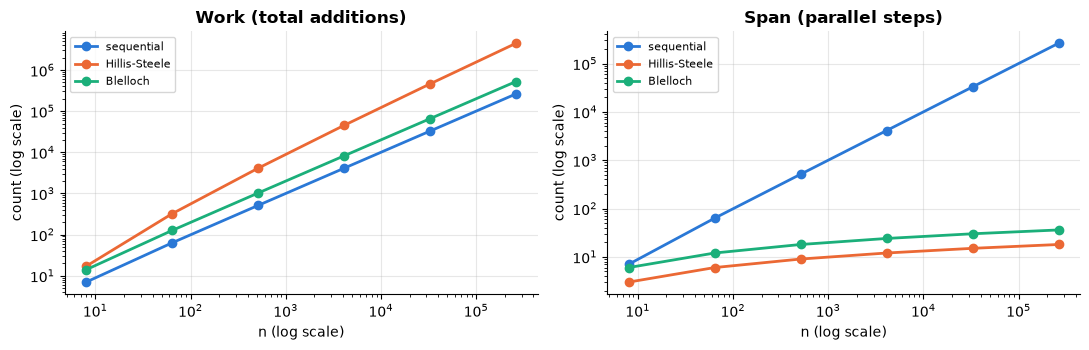

In [8]:
rows = []
for k in range(3, 21, 3):
    n = 2 ** k
    OPS.clear()
    v = np.ones(n, dtype=np.int64)
    _, hs = hillis_steele_scan(v); _, bl, _ = blelloch_scan(v)
    rows.append((n, n - 1, OPS["hillis_steele"], OPS["blelloch"], n - 1, hs, bl))
ops = pd.DataFrame(rows, columns=["n", "work: sequential", "work: Hillis-Steele", "work: Blelloch",
                                  "span: sequential", "span: Hillis-Steele", "span: Blelloch"])
print(ops.to_string(index=False))
assert (ops["work: Blelloch"] == 2 * (ops.n - 1)).all()
assert (ops["work: Hillis-Steele"] == ops.n * np.log2(ops.n) - ops.n + 1).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for col, lab in [("work: sequential", "sequential"), ("work: Hillis-Steele", "Hillis-Steele"), ("work: Blelloch", "Blelloch")]:
    axes[0].loglog(ops.n, ops[col], "o-", label=lab)
for col, lab in [("span: sequential", "sequential"), ("span: Hillis-Steele", "Hillis-Steele"), ("span: Blelloch", "Blelloch")]:
    axes[1].loglog(ops.n, ops[col], "o-", label=lab)
axes[0].set_title("Work (total additions)"); axes[1].set_title("Span (parallel steps)")
for ax in axes:
    ax.set_xlabel("n (log scale)"); ax.set_ylabel("count (log scale)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** The counts match the theory exactly (asserted): Hillis–Steele does $n \log_2 n - n + 1$ additions, about $\log_2 n$ times more than needed, while Blelloch does exactly $2(n - 1)$, twice the sequential work, but in only $2 \log_2 n$ steps. For $n$ ≈ a million, that is 40 parallel steps instead of a million sequential ones.

**Why GPUs use scans.** A GPU runs thousands of threads in lock-step groups, so an algorithm with $O(\log n)$ span and $O(n)$ work keeps them all busy. CUDA's CUB library (`DeviceScan`) and `torch.cumsum` on GPU are built on these ideas (with blocking per thread block). Scan is a **building block** for many other parallel algorithms:
- **stream compaction** (keep the elements that pass a filter, packed together): the exclusive scan of the 0/1 "keep" flags gives each kept element its output position;
- radix sort, sparse-matrix operations, and top-p sampling (the cumulative probabilities);
- **linear recurrences** $h_t = a_t h_{t-1} + b_t$, the core of state-space sequence models such as **Mamba**: the pairs $(a, b)$ combine with an associative operator, so a scan computes all $h_t$ in $O(\log n)$ span.

In [9]:
def compact(values, keep):
    """Stream compaction: positions come from the exclusive scan of the keep flags."""
    flags = np.asarray(keep, dtype=np.int64)
    n2 = 1 << (len(flags) - 1).bit_length()                 # pad to a power of two for blelloch_scan
    pos, _, total = blelloch_scan(np.pad(flags, (0, n2 - len(flags))))
    out = np.empty(total, dtype=np.asarray(values).dtype)
    out[pos[:len(flags)][flags == 1]] = np.asarray(values)[flags == 1]   # a parallel "scatter"
    return out

vals = np.array([5, -2, 8, 0, -7, 3, 9, -1, 4])
print("keep the positive values:", compact(vals, vals > 0), "| boolean indexing:", vals[vals > 0])
assert (compact(vals, vals > 0) == vals[vals > 0]).all()

def assoc_scan(items, op):
    """Hillis-Steele scan for ANY associative operator (inclusive)."""
    y, d = list(items), 1
    while d < len(y):
        y = [y[i] if i < d else op(y[i - d], y[i]) for i in range(len(y))]   # one parallel step
        d *= 2
    return y

# Linear recurrence h_t = a_t * h_{t-1} + b_t as a scan over pairs (a_t, b_t).
# Composing step 1 then step 2: h -> a2*(a1*h + b1) + b2 = (a1*a2)*h + (a2*b1 + b2)
combine = lambda p1, p2: (p1[0] * p2[0], p2[0] * p1[1] + p2[1])
a, b = rng.uniform(0.5, 1.0, 16), rng.normal(size=16)
h_scan = [pair[1] for pair in assoc_scan(list(zip(a, b)), combine)]       # with h_{-1} = 0
h_loop, h = [], 0.0
for at, bt in zip(a, b):
    h = at * h + bt; h_loop.append(h)
assert np.allclose(h_scan, h_loop)
print("linear recurrence via a log-depth scan matches the sequential loop:", np.allclose(h_scan, h_loop))

keep the positive values: [5 8 3 9 4] | boolean indexing: [5 8 3 9 4]
linear recurrence via a log-depth scan matches the sequential loop: True


**Scan on real processes.** On a multi-core CPU the practical algorithm is a **blocked two-pass scan**: (1) each of $p$ workers sums its chunk, (2) a tiny exclusive scan over the $p$ chunk sums gives each chunk its offset, (3) each worker scans its chunk and adds its offset. Work $O(n)$, span $O(n/p + p)$.

In [10]:
def parallel_scan(x, pool, p):
    chunks = np.array_split(x, p)
    sums = list(pool.map(W.chunk_sum, chunks))                       # pass 1: chunk totals (parallel)
    offsets = np.concatenate([[0], np.cumsum(sums)[:-1]])            # tiny serial scan over p numbers
    parts = pool.map(W.chunk_scan, zip(chunks, offsets))             # pass 2: local scans + offsets (parallel)
    return np.concatenate(list(parts))

x = rng.integers(0, 10, 2_000_000)
with ProcessPoolExecutor(MAX_WORKERS) as pool:
    list(pool.map(W.square, range(MAX_WORKERS)))                     # warm-up
    t0 = time.perf_counter(); ys = parallel_scan(x, pool, MAX_WORKERS); t_par = time.perf_counter() - t0
t0 = time.perf_counter(); yc = np.cumsum(x); t_np = time.perf_counter() - t0
assert (ys == yc).all()
print(f"blocked parallel scan on {MAX_WORKERS} processes: correct, {t_par * 1e3:.0f} ms | np.cumsum on 1 core: {t_np * 1e3:.1f} ms")
print(f"bytes shipped to and from the workers ≈ {3 * x.nbytes / 1e6:.0f} MB for a {x.nbytes / 1e6:.0f} MB array")

blocked parallel scan on 4 processes: correct, 260 ms | np.cumsum on 1 core: 12.5 ms
bytes shipped to and from the workers ≈ 48 MB for a 16 MB array


**What just happened?** The process-parallel scan is correct, but much slower than `np.cumsum` on a single core (the exact times are printed above). A scan does just one addition per element, so it is **memory-bound**: the time is dominated by moving data, and our version copies the whole array to the workers and back (pickling). Parallelism pays when there is a lot of computation per byte moved, or when the workers share memory (threads in C code, GPU threads, `multiprocessing.shared_memory`). We will meet this "compute per byte" idea again as **arithmetic intensity** in [`23_Software_Engineering/12`](../../23_Software_Engineering/12_computer_architecture_for_ai_performance.ipynb).

## 4. Parallel merge sort and sample sort

> 💬 **In plain English:** sort pieces on different cores, then combine them; the combining step and data movement decide the real speed-up.

**Intuition.** Sorting splits nicely: different workers sort different piles, then the piles are combined. The combining step is where the difficulty hides.

**Fork-join merge sort (CLRS §26.3).** Sort the two halves **in parallel**, then merge.
- With a **serial merge**: work $\Theta(n \log n)$, span $T_\infty(n) = T_\infty(n/2) + \Theta(n) = \Theta(n)$, parallelism only $\Theta(\log n)$. The final merge is the bottleneck.
- With a **parallel merge** (split the larger array at its median, binary-search that value in the other array, merge the two halves in parallel): span $\Theta(\log^2 n)$ for the merge, $\Theta(\log^3 n)$ for the whole sort, parallelism $\Theta(n / \log^2 n)$.

**Sample sort** (the standard practical algorithm on many cores and clusters):
1. take a random **sample** of $s \cdot p$ elements and sort it; pick $p - 1$ evenly spaced **splitters**;
2. **partition** the data into $p$ buckets by binary search over the splitters;
3. sort the buckets **in parallel**; the concatenation is sorted.

Oversampling ($s$ in the tens to hundreds; we use 256) makes the buckets nearly equal in size with high probability. On clusters, step 2 becomes an all-to-all exchange (the **shuffle** of section 8).

Below, both run on worker processes. The per-chunk sort is a **pure-Python** merge sort, so there is real CPU work to share.

In [11]:
def parallel_merge_sort(data, pool, p):
    chunks = [data[i::p] for i in range(p)]                   # p roughly equal piles
    runs = list(pool.map(W.merge_sort, chunks))               # sorted in parallel
    return list(heapq.merge(*runs))                           # serial p-way merge: O(n log p)

def sample_sort(data, pool, p, oversample=256, seed=0):
    r = random.Random(seed)
    sample = sorted(r.sample(data, min(len(data), oversample * p)))
    splitters = [sample[(i * len(sample)) // p] for i in range(1, p)]
    ids = np.searchsorted(np.array(splitters), np.array(data), side="right")    # bucket of each element
    arr = np.array(data)
    buckets = [arr[ids == b].tolist() for b in range(p)]
    sorted_buckets = list(pool.map(W.merge_sort, buckets))   # independent: no merge needed afterwards
    return list(itertools.chain.from_iterable(sorted_buckets)), [len(b) for b in buckets]

data = [random.random() for _ in range(120_000)]
expected = sorted(data)
timings = {}
t0 = time.perf_counter(); assert W.merge_sort(data) == expected; timings["pure-Python merge sort, 1 core"] = time.perf_counter() - t0
with ProcessPoolExecutor(MAX_WORKERS) as pool:
    list(pool.map(W.square, range(MAX_WORKERS)))
    t0 = time.perf_counter(); assert parallel_merge_sort(data, pool, MAX_WORKERS) == expected
    timings[f"parallel merge sort, {MAX_WORKERS} processes"] = time.perf_counter() - t0
    t0 = time.perf_counter(); out, sizes = sample_sort(data, pool, MAX_WORKERS); assert out == expected
    timings[f"sample sort, {MAX_WORKERS} processes"] = time.perf_counter() - t0
t0 = time.perf_counter(); sorted(data); timings["built-in sorted() (C Timsort), 1 core"] = time.perf_counter() - t0
for k, v in timings.items():
    print(f"{k:42s} {v * 1e3:8.1f} ms")
print("sample-sort bucket sizes:", sizes, f"(largest / average = {max(sizes) / (len(data) / MAX_WORKERS):.3f})")

pure-Python merge sort, 1 core                936.1 ms
parallel merge sort, 4 processes              650.8 ms
sample sort, 4 processes                      686.9 ms
built-in sorted() (C Timsort), 1 core         158.6 ms
sample-sort bucket sizes: [29955, 31393, 28025, 30627] (largest / average = 1.046)


In [12]:
# Where does the time go? Measure the two classic overheads separately.
t0 = time.perf_counter()
with ProcessPoolExecutor(MAX_WORKERS) as pool:
    list(pool.map(W.square, range(MAX_WORKERS)))
startup = time.perf_counter() - t0
t0 = time.perf_counter(); blob = pickle.dumps(data); restored = pickle.loads(blob); pick = time.perf_counter() - t0
print(f"start {MAX_WORKERS} worker processes and shut them down: {startup * 1e3:.0f} ms")
print(f"pickle + unpickle the {len(data):,}-element list once: {pick * 1e3:.1f} ms ({len(blob) / 1e6:.1f} MB)")

start 4 worker processes and shut them down: 163 ms
pickle + unpickle the 120,000-element list once: 31.0 ms (1.1 MB)


**What just happened?** All three sorts produced the correct result (asserted). Compare the printed times: the process-parallel versions are normally faster than the single-core **pure-Python** merge sort, though by less than $p$×, because the serial merge (for merge sort) or the serial partitioning (for sample sort) and the pickling of every element to and from the workers do not parallelise. And the built-in `sorted()`, a single-core C implementation, beats all of them by a wide margin. The bucket sizes (printed with the ratio largest/average) show that splitters taken from a large enough random sample give nearly equal buckets; with fewer samples the ratio grows and the largest bucket becomes the straggler.

⚠️ **Common mistake:** parallelising before optimising. The order of attack is (1) a better algorithm, (2) a better implementation (vectorised / compiled), (3) parallelism. Start-up and pickling costs (printed above) are paid on **every** call, so only large tasks are worth sending to another process.

## 5. Embarrassingly parallel patterns and load balancing

> 💬 **In plain English:** independent tasks are easy to parallelise, but uneven task sizes need smart scheduling.

**Definition.** A workload is **embarrassingly parallel** when it splits into independent tasks with no communication: scoring a million images, a hyper-parameter grid, Monte Carlo simulations, feature extraction per file. The pattern is a parallel **map**, then perhaps a reduce.

Two practical questions remain:
- **Chunking.** Sending each tiny task separately costs a round trip each time; batching tasks into chunks (`chunksize=` in `map`) amortises that cost.
- **Scheduling.** **Static** scheduling gives each worker a fixed share up front (cheap, but slow if tasks differ in length). **Dynamic** scheduling hands out the next task to whichever worker becomes free (a shared queue; balances uneven tasks). **LPT** (longest processing time first) sorts tasks by decreasing length before handing them out dynamically.

Classic guarantees for $p$ identical machines (Graham, 1966/1969): any greedy list schedule has makespan at most $(2 - 1/p)\cdot OPT$; LPT at most $(4/3 - 1/(3p))\cdot OPT$.

Again we use sleeping tasks with known lengths, so the results do not depend on machine noise: 8 long tasks (120 ms) followed by 24 short ones (10 ms), on 4 workers.

In [13]:
durations = [0.12] * 8 + [0.01] * 24
P = 4

def simulate_greedy(durs, p):
    """Makespan of dynamic (greedy list) scheduling: each task goes to the worker that frees up first."""
    free = [0.0] * p
    for d in durs:
        heapq.heapreplace(free, free[0] + d)
    return max(free)

def run_static(durs, p):
    blocks = [durs[i * len(durs) // p:(i + 1) * len(durs) // p] for i in range(p)]   # contiguous shares
    t0 = time.perf_counter()
    with ThreadPoolExecutor(p) as pool:
        list(pool.map(lambda blk: [time.sleep(d) for d in blk], blocks))
    return time.perf_counter() - t0, max(sum(b) for b in blocks)

def run_dynamic(durs, p):
    t0 = time.perf_counter()
    with ThreadPoolExecutor(p) as pool:                  # a shared queue: free workers take the next task
        list(pool.map(time.sleep, durs))
    return time.perf_counter() - t0, simulate_greedy(durs, p)

rows = []
for name, fn, durs in [("static, contiguous blocks", run_static, durations),
                       ("dynamic, original order", run_dynamic, durations),
                       ("dynamic, shuffled order", run_dynamic, random.Random(3).sample(durations, len(durations))),
                       ("dynamic, LPT (longest first)", run_dynamic, sorted(durations, reverse=True))]:
    measured, predicted = fn(durs, P)
    rows.append((name, predicted, measured))
lower_bound = max(sum(durations) / P, max(durations))
sched_df = pd.DataFrame(rows, columns=["schedule", "predicted makespan s", "measured s"]).round(3)
print(sched_df.to_string(index=False))
print(f"lower bound max(total/p, longest task) = {lower_bound:.3f} s")
assert np.allclose(sched_df["predicted makespan s"], sched_df["measured s"], rtol=0.25)

                    schedule  predicted makespan s  measured s
   static, contiguous blocks                  0.96       0.991
     dynamic, original order                  0.30       0.316
     dynamic, shuffled order                  0.31       0.326
dynamic, LPT (longest first)                  0.30       0.317
lower bound max(total/p, longest task) = 0.300 s


**What just happened?** Static contiguous blocks put all 8 long tasks on worker 0, so it needs 0.96 s while the others idle after 0.08 s. Dynamic scheduling hands the long tasks to different workers and finishes in 0.30 s, which here equals the lower bound $\max(\text{total}/p, \text{longest task}) = \max(1.2/4, 0.12) = 0.30$ s. The measured times match the predictions within 25% (asserted). In this particular example even the original order is ideal for dynamic scheduling, because the long tasks happen to come first; LPT guarantees that ordering. Shuffling can be worse, because a long task that arrives late cannot be split.

**Chunk size.** Now the opposite problem: thousands of **tiny** tasks on processes.

In [14]:
items = range(5_000)
rows = []
with ProcessPoolExecutor(MAX_WORKERS) as pool:
    list(pool.map(W.square, range(MAX_WORKERS)))
    for cs in [1, 10, 100, 1000]:
        t0 = time.perf_counter()
        res = list(pool.map(W.square, items, chunksize=cs))
        rows.append((cs, (time.perf_counter() - t0) * 1e3))
        assert res == [i * i for i in items]
t0 = time.perf_counter(); [i * i for i in items]; plain = (time.perf_counter() - t0) * 1e3
chunk_df = pd.DataFrame(rows, columns=["chunksize", "ms for 5,000 tiny tasks"]).round(1)
print(chunk_df.to_string(index=False)); print(f"plain list comprehension in the parent: {plain:.2f} ms")

 chunksize  ms for 5,000 tiny tasks
         1                   2646.6
        10                    248.3
       100                     40.0
      1000                     12.6
plain list comprehension in the parent: 1.10 ms


**What just happened?** With `chunksize=1`, every one of the 5,000 tasks makes its own round trip between processes, and the overhead dwarfs the work (squaring a number). Larger chunks cut the number of round trips by the chunk size, so the time drops sharply from `chunksize=1` to `chunksize=100` (see the table). Beyond that the gain levels off: with only a handful of big chunks, some workers sit idle while the last chunk finishes, and timing noise dominates. Even so, the plain list comprehension in the parent is the fastest of all: each task here is far too small to be worth sending to another process. Rule of thumb: make each task take at least milliseconds, and use chunks of tasks when they are small.

🎓 **Interview tip:** "How would you speed up scoring 10 million rows?" Batch the rows (amortise per-call overhead and use vectorised code), parallelise across processes or machines with **dynamic** scheduling, and put a big-enough chunk in each task.

## 6. The external-memory model and external merge sort

> 💬 **In plain English:** when data does not fit in memory, count block transfers, not operations, and sort in sorted runs plus merges.

**Intuition.** When data lives on disk (or in object storage), the cost of an algorithm is dominated by **how many times it moves data** between disk and memory, and data always moves in big **blocks** (a disk page, an SSD page, a 64 MB HDFS chunk). Counting CPU operations is the wrong measure.

**The model (Aggarwal & Vitter, 1988).** $N$ = number of items, $M$ = items that fit in memory, $B$ = items per block. Cost = number of **block transfers (I/Os)**.

| Task | I/O complexity |
|---|---|
| scan / sum all items | $\Theta(N / B)$ |
| sort | $\Theta\!\left(\frac{N}{B} \log_{M/B} \frac{N}{B}\right)$ (optimal) |
| a B-tree search | $\Theta(\log_B N)$ |

**External merge sort.**
1. **Run formation:** read $M$ items at a time, sort them in memory, write each as a sorted **run**: $\lceil N/M \rceil$ runs, $2N/B$ I/Os.
2. **Merge passes:** merge up to $k = M/B - 1$ runs at a time (one input block per run plus one output block fill the memory). Each pass reads and writes everything ($2N/B$ I/Os) and divides the number of runs by $k$.

$$\text{I/Os} = \frac{2N}{B}\left(1 + \left\lceil \log_k \frac{N}{M} \right\rceil\right)$$

**Worked example (the run below).** $N = 200{,}000$ int64 values, $M = 10{,}000$, $B = 500$: $N/B = 400$ blocks; $20$ runs; $k = 10{,}000/500 - 1 = 19$; merge passes $= \lceil \log_{19} 20 \rceil = 2$ (one pass merges 19 runs, leaving 2). Total $= 2 \times 400 \times 3 = 2{,}400$ I/Os.

In [15]:
IO = Counter()                       # block reads and writes
MEM = {"now": 0, "peak": 0}          # items held in memory by the algorithm

def hold(delta):
    MEM["now"] += delta
    MEM["peak"] = max(MEM["peak"], MEM["now"])

class BlockReader:
    """Reads a file of int64 one block (B items) at a time and hands out items one by one."""
    def __init__(self, path, B):
        self.f, self.B, self.buf, self.i = open(path, "rb"), B, np.empty(0, np.int64), 0
        self._refill()
    def _refill(self):
        hold(-len(self.buf))
        self.buf, self.i = np.fromfile(self.f, dtype=np.int64, count=self.B), 0
        if len(self.buf):
            IO["read"] += 1; hold(len(self.buf))
        else:
            self.f.close()
    def peek(self):
        return self.buf[self.i] if self.i < len(self.buf) else None
    def pop(self):
        v = self.buf[self.i]; self.i += 1
        if self.i == len(self.buf):
            self._refill()
        return v

class BlockWriter:
    """Buffers items and writes them to disk one full block at a time."""
    def __init__(self, path, B):
        self.f, self.B, self.buf = open(path, "wb"), B, []
    def write(self, v):
        self.buf.append(v); hold(1)
        if len(self.buf) == self.B:
            self.flush()
    def flush(self):
        if self.buf:
            np.array(self.buf, dtype=np.int64).tofile(self.f); IO["write"] += 1
            hold(-len(self.buf)); self.buf = []
    def close(self):
        self.flush(); self.f.close()

def external_sort(src, dst, N, M, B, fan_in=None):
    """Sort the int64 file `src` into `dst` holding at most M items in memory. Returns the number of merge passes."""
    k = fan_in or M // B - 1                            # runs merged at once: k input blocks + 1 output block <= M
    assert (k + 1) * B <= M
    tmp = Path(tempfile.mkdtemp(dir=WORK))
    runs = []
    with open(src, "rb") as f:                          # pass 0: run formation
        while True:
            blocks = []
            for _ in range(M // B):
                blk = np.fromfile(f, dtype=np.int64, count=B)
                if not len(blk):
                    break
                IO["read"] += 1; hold(len(blk)); blocks.append(blk)
            if not blocks:
                break
            run = np.sort(np.concatenate(blocks))      # in-memory sort of <= M items
            path = tmp / f"run0_{len(runs)}.bin"
            with open(path, "wb") as out:              # write the run block by block
                for start in range(0, len(run), B):
                    run[start:start + B].tofile(out); IO["write"] += 1
            hold(-len(run)); runs.append(path)
    passes = 0
    while len(runs) > 1:                                # merge passes
        passes += 1
        new_runs = []
        for g in range(0, len(runs), k):
            group = runs[g:g + k]
            out_path = tmp / f"run{passes}_{len(new_runs)}.bin"
            readers = [BlockReader(p, B) for p in group]
            heap = [(r.peek(), i) for i, r in enumerate(readers) if r.peek() is not None]
            heapq.heapify(heap)
            w = BlockWriter(out_path, B)
            while heap:                                 # k-way merge with a heap
                v, i = heapq.heappop(heap)
                w.write(readers[i].pop())
                if readers[i].peek() is not None:
                    heapq.heappush(heap, (readers[i].peek(), i))
            w.close()
            new_runs.append(out_path)
        runs = new_runs
    shutil.copyfile(runs[0], dst)                       # rename, not counted as I/O
    shutil.rmtree(tmp)
    return passes

N, M, B = 200_000, 10_000, 500
data = np.random.default_rng(7).integers(0, 10**9, N, dtype=np.int64)
src, dst = WORK / "big_input.bin", WORK / "sorted_output.bin"
data.tofile(src)
IO.clear(); MEM.update(now=0, peak=0)
passes = external_sort(src, dst, N, M, B)
result = np.fromfile(dst, dtype=np.int64)
assert (result == np.sort(data)).all()
formula = 2 * (N // B) * (1 + math.ceil(math.log(N / M, M // B - 1)))
print(f"N={N:,}, M={M:,}, B={B}: runs={math.ceil(N / M)}, fan-in k={M // B - 1}, merge passes={passes}")
print(f"measured I/Os: {IO['read']} reads + {IO['write']} writes = {IO['read'] + IO['write']} | formula: {formula}")
print(f"peak items held in memory: {MEM['peak']:,} (limit M = {M:,}) | output correct: True")
assert IO["read"] + IO["write"] == formula and MEM["peak"] <= M

N=200,000, M=10,000, B=500: runs=20, fan-in k=19, merge passes=2
measured I/Os: 1200 reads + 1200 writes = 2400 | formula: 2400
peak items held in memory: 10,000 (limit M = 10,000) | output correct: True


**What just happened?** The file had 200,000 values but the algorithm never held more than $M = 10{,}000$ of them at once (tracked and asserted), yet the output is exactly `np.sort` of the input. The measured I/O count, 2,400 block transfers, equals the formula. (Our second merge pass also copies the single leftover run so that every pass reads and writes everything; a real implementation would skip that copy and save a few I/Os.)

The formula says the **fan-in** matters: merging only 2 runs at a time (as in the textbook in-memory merge sort) needs $\lceil \log_2 20 \rceil = 5$ merge passes instead of 2, and more memory reduces the number of runs.

In [16]:
rows = []
for label, M_, B_, k_ in [("binary merges (k = 2)", 10_000, 500, 2),
                          ("full fan-in (k = M/B - 1 = 19)", 10_000, 500, None),
                          ("4x memory (M = 40,000, k = 79)", 40_000, 500, None)]:
    IO.clear(); MEM.update(now=0, peak=0)
    t0 = time.perf_counter()
    passes = external_sort(src, dst, N, M_, B_, fan_in=k_)
    secs = time.perf_counter() - t0
    k_eff = k_ or M_ // B_ - 1
    pred = 2 * (N // B_) * (1 + math.ceil(round(math.log(N / M_, k_eff), 9)))
    assert (np.fromfile(dst, dtype=np.int64) == np.sort(data)).all() and IO["read"] + IO["write"] == pred
    rows.append((label, math.ceil(N / M_), passes, IO["read"] + IO["write"], pred, MEM["peak"], round(secs, 2)))
ext = pd.DataFrame(rows, columns=["configuration", "runs", "merge passes", "measured I/Os", "formula", "peak items", "seconds"])
print(ext.to_string(index=False))

                 configuration  runs  merge passes  measured I/Os  formula  peak items  seconds
         binary merges (k = 2)    20             5           4800     4800       10000     4.34
full fan-in (k = M/B - 1 = 19)    20             2           2400     2400       10000     2.99
4x memory (M = 40,000, k = 79)     5             1           1600     1600       40000     1.20


**What just happened?** Every configuration sorted correctly and matched the I/O formula exactly (asserted). Binary merging needs 5 merge passes and 4,800 I/Os, twice the full fan-in version; with 4× the memory there are only 5 runs, one merge pass and 1,600 I/Os. On a real disk, where one block transfer costs far more than thousands of CPU operations, the I/O count predicts the running time; here the "disk" is the operating system's file cache, so the seconds column mostly reflects our pure-Python merge loop.

**Where you meet this:** database `ORDER BY` and sort-merge joins that spill to disk, Spark's shuffle and sort, LSM-tree compaction in RocksDB/Cassandra ([`08` advanced data structures](08_advanced_data_structures.ipynb)), and sorting or de-duplicating terabyte-scale LLM training corpora. See also [data engineering](../../13_Databases/06_data_engineering/01_data_engineering.ipynb).

⚠️ **Common mistake:** "sorting is $O(n \log n)$, so external sorting is too slow." In I/O terms, $\log_{M/B}(N/B)$ is tiny: with $M/B = 1000$, even a petabyte needs only two or three passes.

## 7. Cache-aware and cache-oblivious algorithms: blocked matrix multiply

> 💬 **In plain English:** arranging loops so data is reused while it is still in the cache can matter more than the number of operations.

**Intuition.** The same external-memory idea applies *inside* the computer: the CPU cache is a small fast memory, RAM is the big slow one, and data moves in **cache lines** of 64 bytes (8 doubles). An algorithm that reuses data while it is still in the cache runs much faster, even with identical operation counts.

**Definitions.**
- A **cache-aware** algorithm uses the cache size explicitly, e.g. **blocked (tiled)** matrix multiply with tiles of $b \times b$ chosen so three tiles fit in the cache ($3b^2 \le M$). It moves $\Theta(n^3 / (B\sqrt{M}))$ cache lines, which is optimal (Hong & Kung, 1981).
- A **cache-oblivious** algorithm achieves the same bound **without knowing** $M$ or $B$, usually by recursive divide and conquer (split each matrix into quadrants until the pieces fit in *whatever* cache exists). It is then good for every level of the hierarchy at once (Frigo, Leiserson, Prokop & Ramachandran, 1999).

Loop order matters too. Matrices in NumPy and C are **row-major**: `B[k, j]` and `B[k, j+1]` are neighbours, but `B[k, j]` and `B[k+1, j]` are $n$ elements apart.

```
ijk:  C[i,j] += A[i,k] * B[k,j]   inner loop over k walks DOWN a column of B  (stride n: a new cache line every step)
ikj:  C[i,j] += A[i,k] * B[k,j]   inner loop over j walks ALONG rows of B and C (stride 1: 8 elements per line)
```

First a hardware-independent experiment: a tiny **simulated** LRU cache counts the misses of each loop order.

In [17]:
class CacheSim:
    """Fully associative LRU cache of `lines` lines, 8 doubles (64 bytes) per line. Counts misses."""
    def __init__(self, lines):
        self.lines, self.cache, self.misses, self.accesses = lines, OrderedDict(), 0, 0
    def touch(self, addr):
        line = addr >> 3                                     # 8 elements per cache line
        self.accesses += 1
        if line in self.cache:
            self.cache.move_to_end(line)
        else:
            self.misses += 1
            self.cache[line] = True
            if len(self.cache) > self.lines:
                self.cache.popitem(last=False)               # evict the least recently used line

def matmul_trace(n, order, cache, bs=8):
    """Feed the addresses touched by C = A @ B (n x n, row-major) to the cache simulator."""
    A, Bm, C = 0, n * n, 2 * n * n                           # base addresses of the three matrices
    t = cache.touch
    if order == "ijk":
        for i in range(n):
            for j in range(n):
                for k in range(n):
                    t(A + i * n + k); t(Bm + k * n + j)
                t(C + i * n + j)                            # C[i,j] accumulated in a register
    elif order == "ikj":
        for i in range(n):
            for k in range(n):
                t(A + i * n + k)
                for j in range(n):
                    t(Bm + k * n + j); t(C + i * n + j)
    else:                                                    # blocked: ikj inside bs x bs tiles
        for ii in range(0, n, bs):
            for kk in range(0, n, bs):
                for jj in range(0, n, bs):
                    for i in range(ii, ii + bs):
                        for k in range(kk, kk + bs):
                            t(A + i * n + k)
                            for j in range(jj, jj + bs):
                                t(Bm + k * n + j); t(C + i * n + j)

n, LINES = 48, 32                                            # 3 matrices of 48x48 doubles vs a 32-line (2 KB) cache
rows = []
for order in ["ijk", "ikj", "blocked"]:
    sim = CacheSim(LINES)
    matmul_trace(n, order, sim)
    rows.append((order, sim.accesses, sim.misses, sim.misses / sim.accesses))
cache_df = pd.DataFrame(rows, columns=["loop order", "accesses", "cache misses", "miss rate"])
print(cache_df.round(4).to_string(index=False))
print(f"compulsory misses (each line loaded once): {3 * n * n // 8}")

loop order  accesses  cache misses  miss rate
       ijk    223488        126720     0.5670
       ikj    223488         14400     0.0644
   blocked    235008          3744     0.0159
compulsory misses (each line loaded once): 864


**What just happened?** All three versions perform the same $n^3$ multiply-adds, but the miss counts differ a lot (printed above). In `ijk`, the inner loop walks down a column of `B`: 48 different cache lines, more than the 32-line cache holds, so almost every access to `B` misses. `ikj` walks along rows, using all 8 elements of each loaded line. The **blocked** version works on 8×8 tiles (3 tiles × 8 lines = 24 lines ≤ 32), so each tile is reused many times while it is cached, and its miss count is the lowest of the three. It makes slightly *more* accesses than `ikj` (each `A[i, k]` is re-read once per tile column), yet far fewer misses: what matters is not how often you touch memory but how often you go to the slow level.

Now real timings. Pure Python is so slow per operation that cache effects barely show, so we also compile the loops with **numba** (optional) and compare with NumPy's `@`, which calls an optimised BLAS library (multi-level blocking, SIMD, several threads).

In [18]:
def py_ijk(A, B):
    n = len(A); C = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            s = 0.0
            for k in range(n):
                s += A[i][k] * B[k][j]
            C[i][j] = s
    return C

def py_ikj(A, B):
    n = len(A); C = [[0.0] * n for _ in range(n)]
    for i in range(n):
        Ci = C[i]
        for k in range(n):
            a, Bk = A[i][k], B[k]
            for j in range(n):
                Ci[j] += a * Bk[j]
    return C

n_py = 120
Ap, Bp = np.random.rand(n_py, n_py), np.random.rand(n_py, n_py)
rows = []
for name, fn in [("pure Python ijk", py_ijk), ("pure Python ikj", py_ikj)]:
    t0 = time.perf_counter(); C = fn(Ap.tolist(), Bp.tolist()); rows.append((name, n_py, time.perf_counter() - t0))
    assert np.allclose(C, Ap @ Bp)

try:
    from numba import njit

    @njit(cache=False)
    def nb_ijk(A, B, C):
        n = A.shape[0]
        for i in range(n):
            for j in range(n):
                s = 0.0
                for k in range(n):
                    s += A[i, k] * B[k, j]
                C[i, j] = s

    @njit(cache=False)
    def nb_ikj(A, B, C):
        n = A.shape[0]
        for i in range(n):
            for k in range(n):
                a = A[i, k]
                for j in range(n):
                    C[i, j] += a * B[k, j]

    @njit(cache=False)
    def nb_blocked(A, B, C, bs):
        n = A.shape[0]                                    # assumes n % bs == 0
        for ii in range(0, n, bs):
            for kk in range(0, n, bs):
                for jj in range(0, n, bs):
                    for i in range(ii, ii + bs):
                        for k in range(kk, kk + bs):
                            a = A[i, k]
                            for j in range(jj, jj + bs):
                                C[i, j] += a * B[k, j]

    n_nb = 512
    An, Bn = np.random.rand(n_nb, n_nb), np.random.rand(n_nb, n_nb)
    for name, fn, extra in [("numba ijk", nb_ijk, ()), ("numba ikj", nb_ikj, ()), ("numba blocked 64x64", nb_blocked, (64,))]:
        fn(An[:64, :64].copy(), Bn[:64, :64].copy(), np.zeros((64, 64)), *extra)   # compile on a small input first
        best = math.inf
        for _ in range(2):
            C = np.zeros((n_nb, n_nb)); t0 = time.perf_counter(); fn(An, Bn, C, *extra); best = min(best, time.perf_counter() - t0)
        assert np.allclose(C, An @ Bn)
        rows.append((name, n_nb, best))
except ImportError:
    n_nb = 512
    An, Bn = np.random.rand(n_nb, n_nb), np.random.rand(n_nb, n_nb)
    print("numba is not installed: skipping the compiled loops (pip install numba to run them)")

best = math.inf
for _ in range(3):
    t0 = time.perf_counter(); An @ Bn; best = min(best, time.perf_counter() - t0)
rows.append(("NumPy @ (BLAS)", n_nb, best))
mm = pd.DataFrame(rows, columns=["implementation", "n", "seconds"])
mm["GFLOP/s"] = 2 * mm.n ** 3 / mm.seconds / 1e9
print(mm.round(4).to_string(index=False))

     implementation   n  seconds  GFLOP/s
    pure Python ijk 120   0.2683   0.0129
    pure Python ikj 120   0.2395   0.0144
          numba ijk 512   0.7475   0.3591
          numba ikj 512   0.1683   1.5946
numba blocked 64x64 512   0.6823   0.3934
     NumPy @ (BLAS) 512   0.0469   5.7258


**What just happened?** Look at the GFLOP/s column (billions of floating-point operations per second, so different $n$ can be compared). In pure Python, loop order hardly matters for the cache, because the interpreter's overhead per operation (tens of nanoseconds) hides memory effects; `ijk` can even be the faster of the two, since its inner loop updates a local variable `s` while `ikj` reads and writes the list element `Ci[j]` on every step. Compiled with numba, the loop order matters a lot: `ijk` strides down columns of `B` and is several times slower than `ikj`, which streams along rows that the compiler can vectorise. Our simple one-level blocked version does **not** beat `ikj` here: its short inner loops (64 iterations) add loop overhead and vectorise less well, while the hardware prefetcher already streams `ikj`'s rows efficiently and the multi-level caches of a real CPU are far larger than the 2 KB toy cache we simulated. The simulator shows *why* blocking can help; real hardware decides *whether* a naive version of it pays off. NumPy's BLAS is far ahead of everything else: it combines blocking for every cache level and for registers, SIMD instructions and multithreading. Lesson: **use the library for standard kernels**, and understand the memory hierarchy for the code the library does not cover. [`23_Software_Engineering/12`](../../23_Software_Engineering/12_computer_architecture_for_ai_performance.ipynb) goes deeper into caches, SIMD and the roofline model.

## 8. Distributed algorithms: MapReduce and ring all-reduce

> 💬 **In plain English:** split work across machines with map, shuffle and reduce, and add up model gradients by passing chunks around a ring.

**Intuition.** On a cluster, the expensive part is the **network**. Algorithms are therefore designed around how much data each machine must send.

### 8.1 MapReduce

**Definition (Dean & Ghemawat, 2004).** A **MapReduce** job is: **map** each input record to zero or more `(key, value)` pairs → **shuffle**: group all pairs with the same key at the same reducer (hash partitioning) → **reduce** each `(key, [values])` group to output. The framework handles splitting, scheduling, re-running failed tasks, and the shuffle (an external sort!). Spark generalises it to multi-stage DAGs kept in memory.

Our tiny in-process engine counts the shuffled records, which stand in for network traffic.

In [19]:
def map_reduce(records, mapper, reducer, n_reducers=4):
    """A miniature MapReduce: map -> hash-partition + group (shuffle) -> reduce. Returns (output, stats)."""
    partitions = [defaultdict(list) for _ in range(n_reducers)]
    shuffled = 0
    for rec in records:                                       # map phase (parallel over input splits in reality)
        for key, value in mapper(rec):
            r = zlib.crc32(repr(key).encode()) % n_reducers    # deterministic hash partitioning
            partitions[r][key].append(value)
            shuffled += 1
    out, load = {}, []
    for part in partitions:                                   # reduce phase (one task per partition)
        load.append(sum(len(v) for v in part.values()))
        for key in sorted(part, key=repr):
            out[key] = reducer(key, part[key])
    return out, {"shuffled records": shuffled, "records per reducer": load}

# 1) Word count, the "hello world" of MapReduce
docs = ["the cat sat on the mat", "the dog sat", "a cat and a dog"]
wc, stats = map_reduce(docs, lambda d: [(w, 1) for w in d.split()], lambda k, vs: sum(vs))
assert wc == Counter(" ".join(docs).split())
print("word count:", dict(sorted(wc.items(), key=lambda kv: -kv[1])[:4]), "|", stats)

# 2) Matrix multiply in one MapReduce round (Leskovec, Rajaraman & Ullman, MMDS §2.3)
I, J, K = 4, 3, 5
Am, Bm = np.random.default_rng(0).integers(0, 5, (I, J)), np.random.default_rng(1).integers(0, 5, (J, K))
records = [("A", i, j, Am[i, j]) for i in range(I) for j in range(J)] + [("B", j, k, Bm[j, k]) for j in range(J) for k in range(K)]
def mm_map(rec):
    name, r, c, v = rec
    if name == "A":                                           # A[i,j] is needed by every C[i,k]
        return [((r, k), ("A", c, v)) for k in range(K)]
    return [((i, c), ("B", r, v)) for i in range(I)]          # B[j,k] is needed by every C[i,k]
def mm_reduce(key, values):
    a = {j: v for t, j, v in values if t == "A"}
    b = {j: v for t, j, v in values if t == "B"}
    return sum(a[j] * b[j] for j in a if j in b)
Cd, stats = map_reduce(records, mm_map, mm_reduce)
C_mr = np.array([[Cd[(i, k)] for k in range(K)] for i in range(I)])
assert (C_mr == Am @ Bm).all()
print("matrix multiply matches NumPy | shuffled records:", stats["shuffled records"], "= 2*I*J*K =", 2 * I * J * K)

# 3) Reduce-side join of users and events on user_id, checked against pandas
users = pd.DataFrame({"user_id": range(6), "country": ["PK", "DE", "PK", "US", "FR", "PK"]})
events = pd.DataFrame({"user_id": [0, 0, 0, 0, 0, 0, 1, 2, 2, 3, 5, 9], "item": list("abcdefghijkl")})
recs = [("U", r.user_id, r.country) for r in users.itertuples()] + [("E", r.user_id, r.item) for r in events.itertuples()]
def join_reduce(uid, values):
    us = [v for t, v in values if t == "U"]
    es = [v for t, v in values if t == "E"]
    return [(uid, c, it) for c in us for it in es]           # inner join = cross product per key
joined, stats = map_reduce(recs, lambda r: [(r[1], (r[0], r[2]))], join_reduce)
mr_rows = sorted(row for rows_ in joined.values() for row in rows_)
pd_rows = sorted(map(tuple, users.merge(events, on="user_id")[["user_id", "country", "item"]].values.tolist()))
assert mr_rows == pd_rows
print(f"join: {len(mr_rows)} rows, same as pandas.merge | records per reducer: {stats['records per reducer']}")

word count: {'the': 3, 'sat': 2, 'a': 2, 'cat': 2} | {'shuffled records': 14, 'records per reducer': [1, 4, 4, 5]}
matrix multiply matches NumPy | shuffled records: 120 = 2*I*J*K = 120
join: 11 rows, same as pandas.merge | records per reducer: [1, 11, 2, 4]


**What just happened?** All three MapReduce programs agree with the direct computation (asserted). The one-round matrix multiply shuffles $2IJK$ records: each element of $A$ is copied to $K$ reducers and each element of $B$ to $I$ reducers. That replication is the price of doing it in one round; a two-round algorithm shuffles less for large matrices, which is the kind of **communication-cost** trade-off this field studies (MMDS ch. 2). In the join, user 0 has 6 of the 12 events, so the reducer that receives key 0 gets more records than the others (see "records per reducer"). This **data skew** ("hot keys") is the most common reason a real Spark or MapReduce job has one straggling task; fixes include salting hot keys and broadcast joins.

### 8.2 Ring all-reduce

**Definition.** In data-parallel training, each of $p$ workers computes a gradient vector of length $N$ and they all need the **sum** (an **all-reduce**). **Ring all-reduce** arranges the workers in a ring and splits each vector into $p$ chunks:
1. **Reduce-scatter** ($p - 1$ steps): each worker sends one chunk to its right neighbour, which adds it to its own copy. Afterwards, each worker owns the complete sum of one chunk.
2. **All-gather** ($p - 1$ steps): the completed chunks travel around the ring, overwriting.

Each worker sends $2(p - 1) \cdot N/p$ values in total, which is **almost independent of $p$** and optimal for bandwidth (Patarasuk & Yuan, 2009). A naive "everyone sends to worker 0, worker 0 sends the sum back" makes worker 0 receive and send $(p - 1)N$ values. NCCL (the library PyTorch DDP uses on NVIDIA GPUs) implements ring and tree variants.

 workers p  gradient length N  ring: sent per worker  formula 2(p-1)N/p  naive: worker 0 sends
         2               4800                   4800               4800                   4800
         4               4800                   7200               7200                  14400
         8               4800                   8400               8400                  33600
        16               4800                   9000               9000                  72000

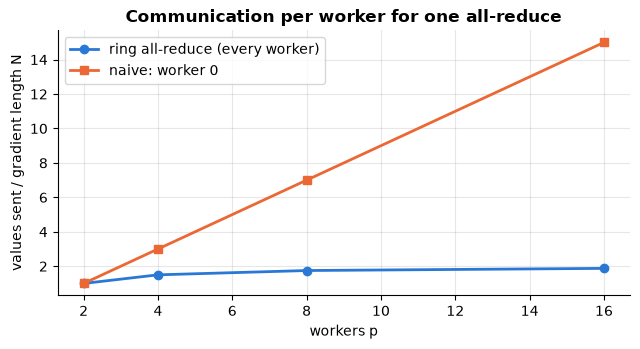

In [20]:
def ring_allreduce(grads):
    """Simulate ring all-reduce on a (p, N) array, N divisible by p. Returns (results, values sent per worker)."""
    p, N = grads.shape
    chunks = [np.array_split(g.astype(float), p) for g in grads]       # chunks[worker][c]
    sent = np.zeros(p, dtype=int)
    for step in range(p - 1):                                           # reduce-scatter
        msgs = [(w, (w - step) % p, chunks[w][(w - step) % p].copy()) for w in range(p)]   # snapshot: all send at once
        for w, c, payload in msgs:
            chunks[(w + 1) % p][c] += payload; sent[w] += len(payload)
    for step in range(p - 1):                                           # all-gather
        msgs = [(w, (w + 1 - step) % p, chunks[w][(w + 1 - step) % p].copy()) for w in range(p)]
        for w, c, payload in msgs:
            chunks[(w + 1) % p][c] = payload; sent[w] += len(payload)
    return np.array([np.concatenate(c) for c in chunks]), sent

def naive_allreduce_traffic(p, N):
    return {"worker 0 sends": (p - 1) * N, "worker 0 receives": (p - 1) * N, "others send": N}

rng = np.random.default_rng(0)
rows = []
for p in [2, 4, 8, 16]:
    N = 4_800                                                         # divisible by every p used here
    g = rng.normal(size=(p, N))
    res, sent = ring_allreduce(g)
    assert np.allclose(res, g.sum(0))                                # every worker holds the full sum
    assert (sent == 2 * (p - 1) * N // p).all()
    rows.append((p, N, sent[0], 2 * (p - 1) * N // p, naive_allreduce_traffic(p, N)["worker 0 sends"]))
ar = pd.DataFrame(rows, columns=["workers p", "gradient length N", "ring: sent per worker", "formula 2(p-1)N/p",
                                 "naive: worker 0 sends"])
print(ar.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ar["workers p"], ar["ring: sent per worker"] / 4_800, "o-", label="ring all-reduce (every worker)")
ax.plot(ar["workers p"], ar["naive: worker 0 sends"] / 4_800, "s-", label="naive: worker 0")
ax.set_xlabel("workers p"); ax.set_ylabel("values sent / gradient length N")
ax.set_title("Communication per worker for one all-reduce"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** After the simulated $2(p-1)$ steps, every worker held exactly the sum of all gradients, and each sent exactly $2(p-1)N/p$ values (both asserted). For 16 workers that is 9,000 values, under 2× the gradient length, while the naive scheme's worker 0 must send 72,000 (15×) and becomes the bottleneck. In the **α–β cost model** (α = latency per message, β = time per value), ring time is $2(p - 1)\alpha + 2\frac{p-1}{p} N \beta$: bandwidth-optimal, but the latency term grows with $p$, which is why large clusters use **tree** or **hierarchical** all-reduce for small messages. See [`05_Deep_Learning/11_distributed_training`](../../05_Deep_Learning/11_distributed_training.ipynb) for DDP, FSDP and ZeRO, which build on these collectives.

**Consensus and clocks** (Paxos/Raft, Lamport and vector clocks, the CAP theorem) are the other half of distributed computing; they are covered in [`23_Software_Engineering/09` system design](../../23_Software_Engineering/09_system_design_fundamentals.ipynb).

## 🔗 How this connects to modern AI

| Idea from this notebook | Where it shows up in AI systems |
|---|---|
| Work/span, Amdahl | why adding GPUs gives diminishing returns when data loading, logging or the optimizer step stays serial; profiling the serial fraction is the first step in scaling training |
| Gustafson | why we scale **batch size and model size** with the cluster (weak scaling) instead of training a fixed model faster |
| Parallel scan | GPU `cumsum`, top-p sampling, stream compaction in data loaders, and the **selective scan** of state-space models (Mamba, Gu & Dao 2023) |
| Reduction trees | softmax and layer-norm denominators on GPU, `torch.sum`, gradient all-reduce |
| Sample sort / shuffle | Spark and Ray Data shuffles when building training sets; distributed sorting for de-duplication |
| External merge sort | sorting and de-duplicating web-scale pre-training corpora that do not fit in RAM; database spills ([`13_Databases`](../../13_Databases/06_data_engineering/01_data_engineering.ipynb)) |
| Cache blocking / tiling | **FlashAttention** tiles attention so blocks stay in fast on-chip SRAM, the same idea as section 7 applied to GPU memory |
| Ring all-reduce | PyTorch DDP and NCCL in every multi-GPU training run ([`05_Deep_Learning/11`](../../05_Deep_Learning/11_distributed_training.ipynb)) |
| Load balancing | batching variable-length sequences ("bucketing") so GPUs are not idle waiting for the longest sequence |

## Recap

- Analyse parallel algorithms by **work** $T_1$ and **span** $T_\infty$; parallelism is $T_1/T_\infty$, and a greedy scheduler achieves $T_p \le T_1/p + T_\infty$ (Brent).
- **Amdahl:** the serial fraction $s$ caps the speed-up at $1/s$. **Gustafson:** if the problem grows with $p$, the scaled speed-up is $s + p(1-s)$.
- **Scan** is not inherently sequential: Blelloch's scan does $O(n)$ work in $O(\log n)$ span and is a building block for compaction, sorting and linear recurrences.
- Parallel sorting: merge sort is limited by the merge; **sample sort** partitions with splitters so buckets can be sorted independently.
- Real overheads (process start-up, pickling, memory bandwidth, contention) mean measured speed-ups fall below the models; small or memory-bound tasks may not benefit at all.
- Use **dynamic scheduling** (or LPT) for uneven tasks and **chunking** for tiny ones.
- In the **external-memory model**, count block I/Os; external merge sort costs $\frac{2N}{B}(1 + \lceil \log_{M/B - 1} \frac{N}{M} \rceil)$ I/Os, and large fan-in keeps the number of passes tiny.
- Loop order and **blocking** change cache misses without changing the arithmetic; optimised libraries (BLAS) combine all of these tricks.
- **MapReduce** = map, shuffle, reduce; watch replication and skew. **Ring all-reduce** sends $2(p-1)N/p$ values per worker.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy)** A data pipeline spends 20% of its single-core time in a serial step. (a) What speed-up does Amdahl's law predict on 8 cores? (b) With infinitely many cores? (c) What scaled speed-up does Gustafson's law give on 8 cores if the serial step is 20% of the *parallel* run time?

<details><summary>Show solution</summary>

(a) $S(8) = 1 / (0.2 + 0.8/8) = 1/0.3 \approx 3.33$. (b) $1/0.2 = 5$. (c) $0.2 + 8 \times 0.8 = 6.6$.

</details>

**2. (Easy)** Summing $n = 1024$ numbers with a balanced tree: give the work, the span, the parallelism, and Brent's upper bound on $T_8$.

<details><summary>Show solution</summary>

Work $T_1 = n - 1 = 1023$ additions; span $T_\infty = \log_2 1024 = 10$; parallelism $1023/10 \approx 102$. Brent: $T_8 \le 1023/8 + 10 \approx 137.9$ steps (and at least $\lceil 1023/8 \rceil = 128$ by the work law).

</details>

**3. (Medium, coding)** Write a running-**maximum** scan in $\lceil \log_2 n \rceil$ vectorised Hillis–Steele steps. Why does the same algorithm work for max as for sum?

<details><summary>Show solution</summary>

The scan only needs the operator to be **associative** (`max(max(a, b), c) == max(a, max(b, c))`); identity and inverses are not required for Hillis–Steele.

```python
import numpy as np

def running_max_scan(x):
    """Inclusive running maximum with Hillis-Steele steps: log2(n) vectorised steps."""
    y, d, steps = np.array(x, dtype=float), 1, 0
    while d < len(y):
        new = y.copy()
        new[d:] = np.maximum(y[d:], y[:-d])        # any associative operator works
        y, d, steps = new, 2 * d, steps + 1
    return y, steps
```
Tested against `np.maximum.accumulate` for several sizes, including non-powers of two.

</details>

**4. (Medium)** You must sort $N = 10^9$ records of 100 bytes (100 GB) with $M = 1$ GB of RAM and blocks of $B = 1$ MB. How many runs, merge passes and block I/Os does external merge sort need? How much data is read and written in total?

<details><summary>Show solution</summary>

In blocks: $N/B = 100\text{ GB} / 1\text{ MB} = 100{,}000$ blocks, $M/B = 1000$, so the fan-in is $k = 999$. Run formation makes $100 / 1 = 100$ runs; $100 \le 999$, so **one** merge pass. I/Os $= 2 \times 100{,}000 \times (1 + 1) = 400{,}000$ block transfers: 200 GB read and 200 GB written (each byte is read twice and written twice).

</details>

**5. (Medium, coding)** Implement **stream compaction** with an exclusive scan: given `values` and a boolean `keep`, return the kept values in order, where each element's output position comes from the scan.

<details><summary>Show solution</summary>

```python
import numpy as np

def compact_np(values, keep):
    """Stream compaction: output position of each kept element = exclusive scan of the keep flags."""
    values, keep = np.asarray(values), np.asarray(keep, dtype=bool)
    flags = keep.astype(np.int64)
    pos = np.cumsum(flags) - flags            # exclusive scan
    out = np.empty(flags.sum(), dtype=values.dtype)
    out[pos[keep]] = values[keep]             # scatter: every kept element writes independently
    return out
```
Every kept element can write to its position independently, so on a GPU this is a scan plus a parallel scatter: $O(n)$ work, $O(\log n)$ span. Tested against boolean indexing on 200 random arrays.

</details>

**6. (Hard, coding)** Implement a **tree all-reduce** (binary-tree reduce to worker 0, then broadcast down the same tree) for any $p$. Count steps and values sent per worker, and compare with ring all-reduce.

<details><summary>Show solution</summary>

```python
import numpy as np

def tree_allreduce(grads):
    """Binary-tree reduce to worker 0, then broadcast back down. Returns (results, values sent per worker, steps)."""
    p, N = grads.shape
    vals = [g.astype(float).copy() for g in grads]
    sent, steps = np.zeros(p, dtype=int), 0
    d = 1
    while d < p:                               # reduce: worker w + d sends to w for w multiple of 2d
        for w in range(0, p, 2 * d):
            if w + d < p:
                vals[w] += vals[w + d]; sent[w + d] += N
        d, steps = 2 * d, steps + 1
    d //= 2
    while d >= 1:                              # broadcast: reverse the tree
        for w in range(0, p, 2 * d):
            if w + d < p:
                vals[w + d] = vals[w].copy(); sent[w] += N
        d, steps = d // 2, steps + 1
    return np.array(vals), sent, steps
```
Tree: $2\lceil \log_2 p \rceil$ steps, and some workers send up to $2\lceil\log_2 p\rceil \cdot N$ values (whole vectors). Ring: $2(p-1)$ steps but only $2(p-1)N/p < 2N$ values per worker. So the tree wins on **latency** (few steps, good for small messages) and the ring wins on **bandwidth** (large gradients). Tested for $p = 1 \dots 16$ including non-powers of two.

</details>

**7. (Hard, conceptual)** Why did GPU training frameworks move from a central **parameter server** to all-reduce, and why does FlashAttention count as a "cache-aware" algorithm?

<details><summary>Show solution</summary>

A parameter server receives every worker's full gradient, so its network link carries $(p-1)N$ values per step and becomes a bottleneck as $p$ grows; ring/tree all-reduce spreads the traffic so each link carries $O(N)$ regardless of $p$, and it maps well onto NVLink/InfiniBand topologies. FlashAttention (Dao et al., 2022) never writes the $n \times n$ attention matrix to GPU HBM; it processes $Q$, $K$, $V$ in tiles that fit in on-chip SRAM, using an online softmax to combine tiles. This is exactly section 7's blocking: the same FLOPs with far fewer slow-memory transfers, which is what makes it faster.

</details>

## Further reading

- Cormen, Leiserson, Rivest & Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022), ch. 26 "Parallel Algorithms" (fork-join model, work/span, greedy scheduling, parallel merge sort).
- G. E. Blelloch, "Prefix Sums and Their Applications" (CMU tech report, 1990); W. D. Hillis & G. L. Steele, "Data Parallel Algorithms", *CACM* 1986; M. Harris, S. Sengupta & J. Owens, "Parallel Prefix Sum (Scan) with CUDA", *GPU Gems 3*, ch. 39 (free online).
- G. M. Amdahl (1967); J. L. Gustafson, "Reevaluating Amdahl's Law", *CACM* 1988; R. L. Graham, "Bounds on multiprocessing timing anomalies", 1969.
- A. Aggarwal & J. S. Vitter, "The input/output complexity of sorting and related problems", *CACM* 1988; M. Frigo, C. Leiserson, H. Prokop & S. Ramachandran, "Cache-oblivious algorithms", FOCS 1999.
- J. Dean & S. Ghemawat, "MapReduce: Simplified Data Processing on Large Clusters", OSDI 2004; J. Leskovec, A. Rajaraman & J. Ullman, *Mining of Massive Datasets*, ch. 2 (free at [mmds.org](http://www.mmds.org/)).
- P. Patarasuk & X. Yuan, "Bandwidth optimal all-reduce algorithms for clusters of workstations", *JPDC* 2009; the [NCCL documentation](https://docs.nvidia.com/deeplearning/nccl/user-guide/docs/index.html).

## Next notebook
➡️ [`23_Software_Engineering/12` · Computer architecture for AI performance](../../23_Software_Engineering/12_computer_architecture_for_ai_performance.ipynb): bits and floating-point formats, caches, SIMD, the roofline model and GPU arithmetic intensity, the hardware view of everything in this notebook.

⬅️ Previous: [09 · Coding interview workbook](09_coding_interview_workbook.ipynb)

## Clean up

In [21]:
sys.path.remove(str(WORK))
sys.modules.pop("aa10_workers", None)
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True
